# Random Forest con features geoespaciales

**Escenario:** geo (variables base + `distancia_*` + `cluster_zona`).

**Objetivo:** medir el aporte de las features geoespaciales manteniendo el mismo split estratificado, la misma semilla y los mejores hiperparámetros encontrados en la baseline.

- Entrada: `data/processed/airprice_features.csv`
- Split: `split_estratificado(..., excluir=['price_clean', 'id'], seed=42)`
- Preprocesador: `src/preprocessing_features.py` (los clusters se tratan como categóricos con One-Hot).
- Salidas: `reports/random_forest_features_metricas.csv`, importancia de variables y matriz de confusión.

> No se modifica el notebook baseline. La comparación es justa porque se descartan exactamente las mismas columnas que en la baseline (`COLUMNAS_DESCARTADAS`).

In [1]:
import sys
sys.path.append('../..')

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.model_features import (
    PARAMS_BASE,
    construir_rf_features,
    evaluar_modelo_ordinal,
    importancia_variables,
    metricas_a_fila,
)
from src.preprocessing_features import FEATURES_PATH, preparar_dataset_features
from src.utils import (
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)

sns.set_theme(style='whitegrid')
fijar_semilla(SEED)
print('Semilla:', SEED)

Semilla: 42


In [2]:
df = preparar_dataset_features(cargar_dataset(FEATURES_PATH))
print('Filas:', df.shape[0], 'Columnas:', df.shape[1])

X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target='price_range',
    excluir=['price_clean', 'id'],
    seed=SEED,
)
print('Train:', X_train.shape, 'Val:', X_val.shape, 'Test:', X_test.shape)

geo = [
    c for c in X_train.columns
    if c.startswith('distancia_') or c.startswith('cluster_zona')
]
print('Features geo:', geo)
print('price_clean en X_train:', 'price_clean' in X_train.columns)
print('price_range en X_train:', 'price_range' in X_train.columns)

Filas: 61617 Columnas: 29
Train: (43131, 28) Val: (9243, 28) Test: (9243, 28)
Features geo: ['distancia_centro_km', 'distancia_heathrow_km', 'distancia_kings_cross_km', 'distancia_hyde_park_km', 'distancia_canary_wharf_km', 'cluster_zona']
price_clean en X_train: False
price_range en X_train: False


In [3]:
params = dict(PARAMS_BASE['random_forest'])
print('Hiperparámetros baseline:', params)

modelo = construir_rf_features(X_train, **params)
modelo.fit(X_train, y_train)

met_val = evaluar_modelo_ordinal(y_val, modelo.predict(X_val))
print({k: round(v, 4) for k, v in met_val.items() if k != 'matriz_confusion'})

Hiperparámetros baseline: {'n_estimators': 100, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}
{'accuracy': 0.6895, 'balanced_accuracy': 0.6891, 'f1_macro': 0.6875, 'f1_weighted': 0.6878, 'accuracy_adjacent': 0.9682, 'mae_ordinal': 0.3475, 'qwk': 0.8293}


{'accuracy': 0.687, 'balanced_accuracy': 0.6866, 'f1_macro': 0.6846, 'f1_weighted': 0.6849, 'accuracy_adjacent': 0.9669, 'mae_ordinal': 0.3529, 'qwk': 0.8241}


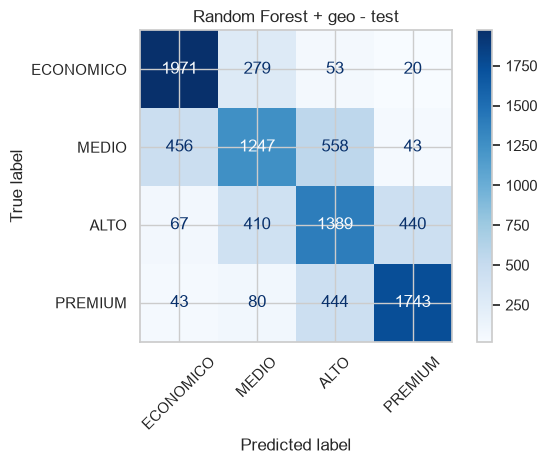

In [4]:
y_pred = modelo.predict(X_test)
met_test = evaluar_modelo_ordinal(y_test, y_pred)
print({k: round(v, 4) for k, v in met_test.items() if k != 'matriz_confusion'})

ConfusionMatrixDisplay(
    met_test['matriz_confusion'], display_labels=CLASES
).plot(cmap='Blues', values_format='d')
plt.title('Random Forest + geo - test')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'random_forest_features_matriz_confusion.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

                          variable  importancia
0                num__accommodates     0.062074
1      num__distancia_hyde_park_km     0.061428
2         num__distancia_centro_km     0.060953
3    num__distancia_kings_cross_km     0.054567
4                    num__latitude     0.050093
5             num__amenities_count     0.049842
6            num__availability_365     0.048691
7       num__distancia_heathrow_km     0.047902
8                   num__longitude     0.047617
9   num__distancia_canary_wharf_km     0.047273
10  cat__room_type_Entire home/apt     0.046846
11                   num__bedrooms     0.042205
12     cat__room_type_Private room     0.041009
13          num__reviews_per_month     0.038672
14              num__bathrooms_num     0.037891


C:\Users\user\AppData\Local\Temp\ipykernel_10920\3783177754.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top, x='importancia', y='variable', palette='viridis')


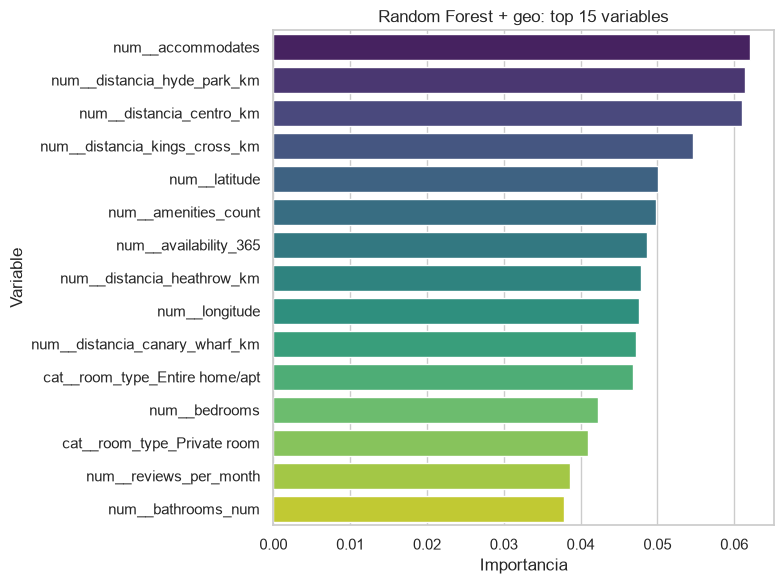

In [5]:
importancia = importancia_variables(modelo)
importancia.to_csv(
    REPORTS_DIR / 'random_forest_features_importancia.csv', index=False
)
print(importancia.head(15))

top = importancia.head(15)
plt.figure(figsize=(8, 6))
sns.barplot(data=top, x='importancia', y='variable', palette='viridis')
plt.title('Random Forest + geo: top 15 variables')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.tight_layout()
plt.savefig(
    REPORTS_DIR / 'random_forest_features_importancia.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

In [6]:
fila = metricas_a_fila(
    'random_forest_features',
    met_test,
    escenario='geo',
    **params,
)
pd.DataFrame([fila]).to_csv(
    REPORTS_DIR / 'random_forest_features_metricas.csv', index=False
)

ruta = guardar_modelo(modelo, 'random_forest_features')
print('Métricas y matriz guardadas en:', REPORTS_DIR)
print('Modelo guardado en:', ruta)

Métricas y matriz guardadas en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports
Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\random_forest_features.joblib


## Lectura de resultados

- `accuracy_adjacent` indica el acierto exacto **o en la clase vecina**; para un target ordinal es la métrica de negocio más informativa.
- `mae_ordinal` y `qwk` cuantifican cuán lejos están los errores.
- La importancia de variables permite ver si `distancia_*` o `cluster_zona` entran al top. Si no entran, es esperable: `latitude` y `longitude` ya estaban en la baseline y las distancias son transformaciones deterministas de ellas.
- El modelo se guarda como `random_forest_features.joblib` para no sobrescribir el baseline.